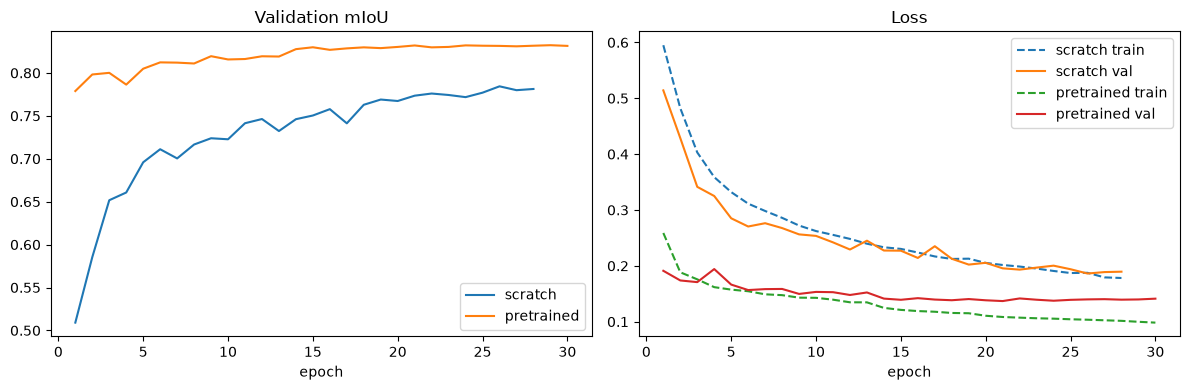

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

scratch = pd.read_csv("../outputs/unet_scratch_log.csv")
pre = pd.read_csv("../outputs/unet_pretrained_log.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(scratch["epoch"], scratch["val_miou"], label="scratch")
axes[0].plot(pre["epoch"], pre["val_miou"], label="pretrained")
axes[0].set_title("Validation mIoU")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(scratch["epoch"], scratch["train_loss"], "--", label="scratch train")
axes[1].plot(scratch["epoch"], scratch["val_loss"], label="scratch val")
axes[1].plot(pre["epoch"], pre["train_loss"], "--", label="pretrained train")
axes[1].plot(pre["epoch"], pre["val_loss"], label="pretrained val")
axes[1].set_title("Loss")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig("../outputs/training_curves.png", dpi=150)
plt.show()

In [2]:
import sys
sys.path.append("..")

import numpy as np
import torch
from src.dataset import get_dataloaders
from src.model import PretrainedUNet

device = "cuda"
_, _, test_loader = get_dataloaders(
    csv_path="../data/processed/split.csv",
    image_folder="../data/raw/oxford-iiit-pet/images",
    trimap_folder="../data/raw/oxford-iiit-pet/annotations/trimaps",
    image_size=256, batch_size=8, num_workers=0,
)

model = PretrainedUNet(pretrained=False).to(device)
model.load_state_dict(torch.load("../models/unet_pretrained_best.pth", map_location=device))
model.eval()

records = []   # (image, mask, pred, miou) per test image
with torch.no_grad():
    for images, masks in test_loader:
        preds = model(images.to(device)).argmax(dim=1).cpu()
        for img, m, p in zip(images, masks, preds):
            ious = []
            for c in range(3):
                inter = ((m == c) & (p == c)).sum().item()
                union = ((m == c) | (p == c)).sum().item()
                if union > 0:
                    ious.append(inter / union)
            records.append((img, m, p, float(np.mean(ious))))

scores = np.array([r[3] for r in records])
print("images scored:", len(scores))
print("mean per-image mIoU:", scores.mean().round(4))
print("median:", np.median(scores).round(4), "| worst:", scores.min().round(4), "| best:", scores.max().round(4))
print("images below 0.5:", (scores < 0.5).sum())

d:\Dl projects\segmentation-Unet\.venv\Lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


images scored: 1101
mean per-image mIoU: 0.8213
median: 0.8363 | worst: 0.167 | best: 0.9195
images below 0.5: 6


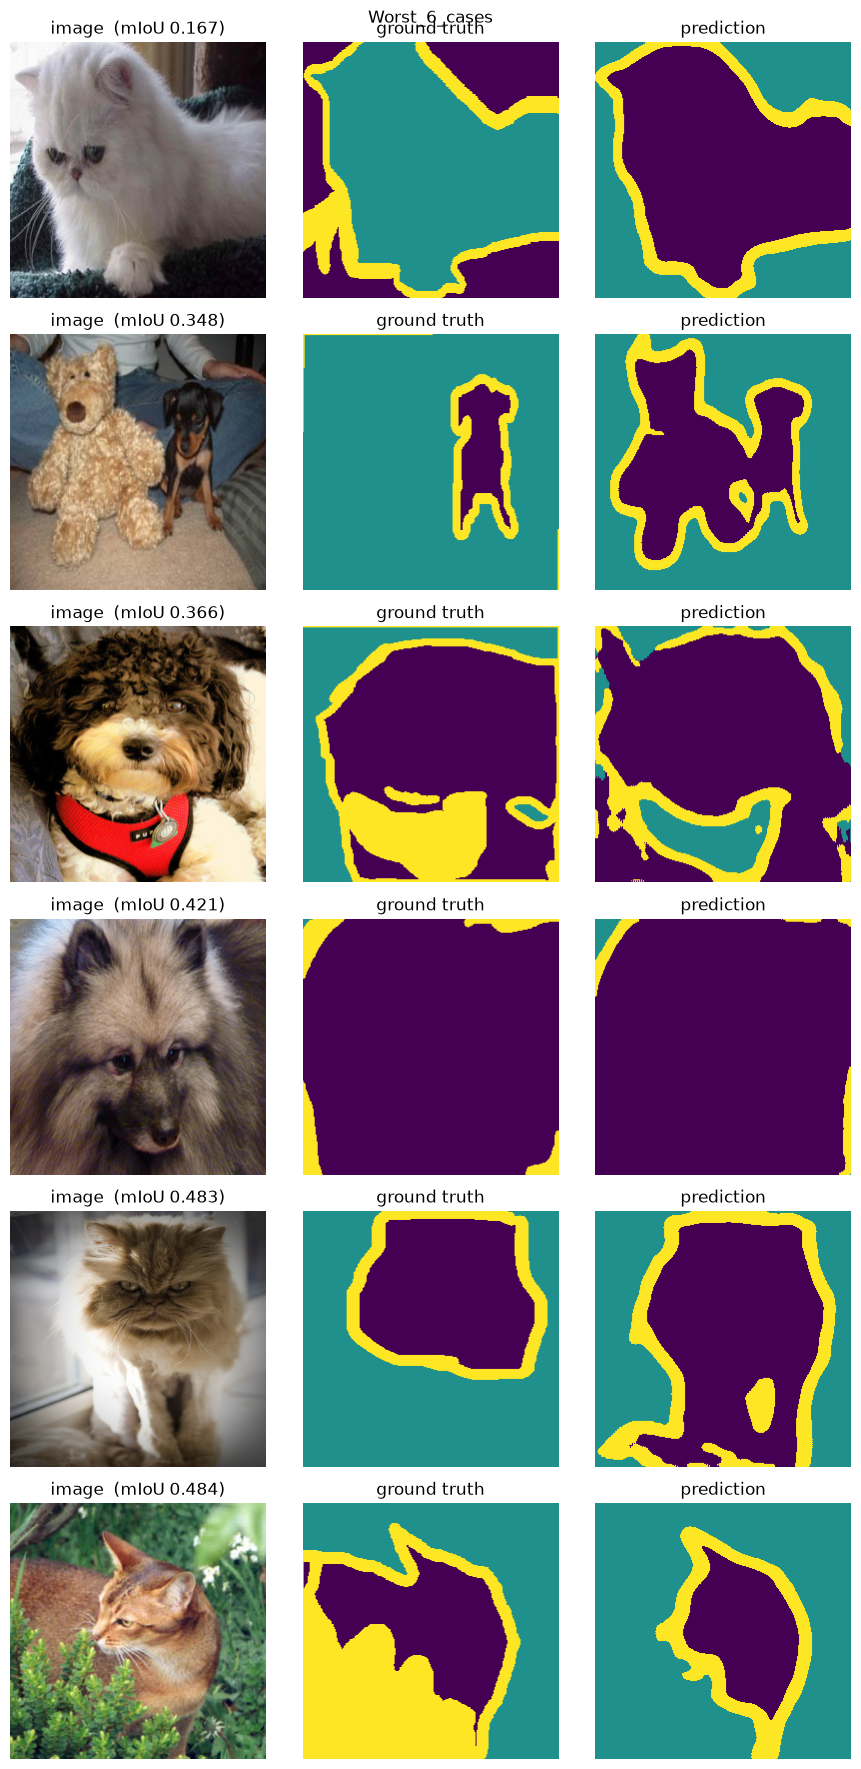

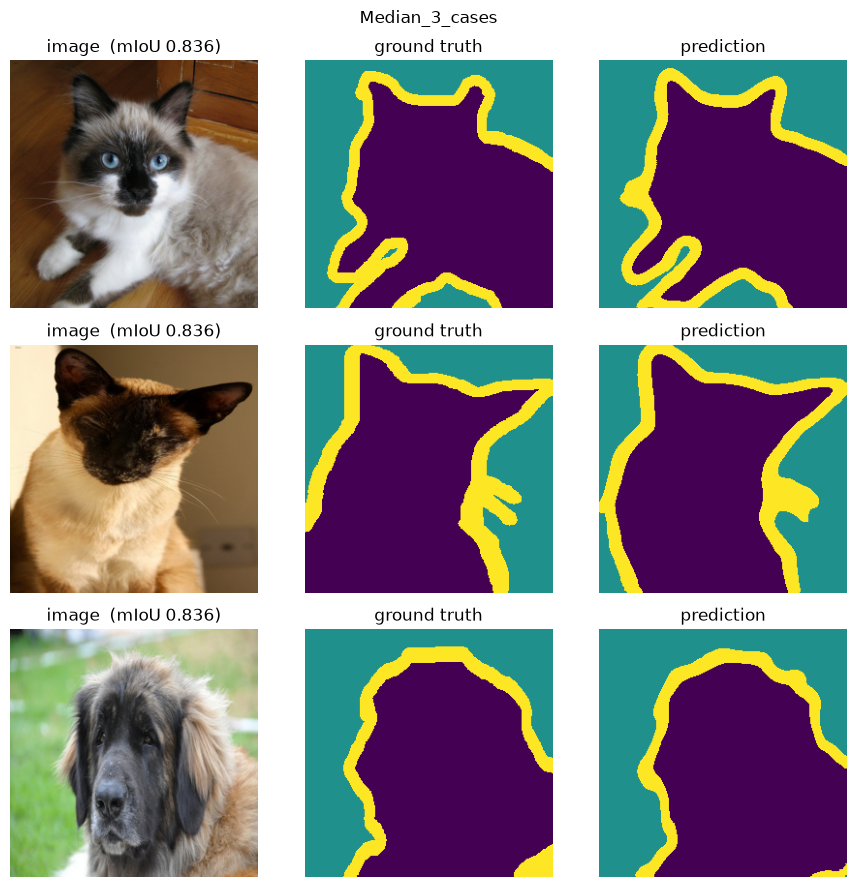

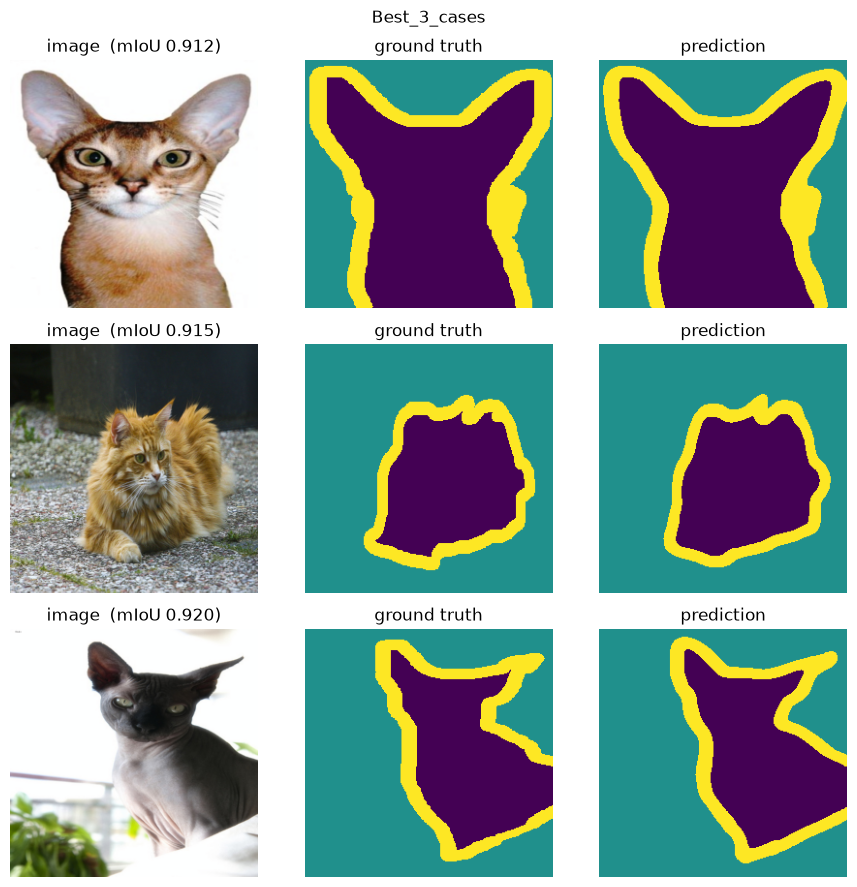

In [4]:
import matplotlib.pyplot as plt

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

def show_rows(indices, title):
    fig, axes = plt.subplots(len(indices), 3, figsize=(9, 3 * len(indices)))
    for row, i in enumerate(indices):
        img, m, p, s = records[i]
        img = (img.permute(1, 2, 0).numpy() * std + mean).clip(0, 1)
        axes[row, 0].imshow(img)
        axes[row, 0].set_title(f"image  (mIoU {s:.3f})")
        axes[row, 1].imshow(m, vmin=0, vmax=2, cmap="viridis")
        axes[row, 1].set_title("ground truth")
        axes[row, 2].imshow(p, vmin=0, vmax=2, cmap="viridis")
        axes[row, 2].set_title("prediction")
        for a in axes[row]:
            a.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(f"../outputs/{title}.png", dpi=150, bbox_inches="tight")
    plt.show()

order = np.argsort(scores)
show_rows(order[:6], "Worst_6_cases")
show_rows(order[len(order)//2 - 1 : len(order)//2 + 2], "Median_3_cases")
show_rows(order[-3:], "Best_3_cases")